# Ảnh hưởng của phân phối biến nhiễu đến chất lượng ước lượng ATE

In [1]:
import os, sys
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from distribution import Simulation, SCENARIOS
from balance import check_balance, summarize, iptw_weights
from methods import estimate_all
# Tham số 
SEED=251
N=2000

# --- Giao diện biểu đồ: nền sáng, nét mảnh, lưới nhạt ---
BLUE, ORANGE, AQUA, MUTED, INK = "#3fa6e1", "#e04444", "#d26f28", "#7ED386", "#0b0b0b"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "axes.titlesize": 10, "axes.titleweight": "regular",
    "axes.titlelocation": "center", "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

Simulation.list_scenarios()

,id,name,description
0,1,baseline,"X1~N(0;1), X2~N(0;1)"
1,2,weak_overlap,"X1~N(0;1), X2~N(0;9)"
2,3,outlier,"X1~N(0;1), X2~t(df=2)"
3,4,skewed,"X1~N(0;1), X2~Exp(1)-1"
4,5,bimodal,"X1~N(0;1), X2~Bimodal"
5,6,skewed_outlier,"X1~Exp(1)-1, X2~t(df=2)"
6,7,skewed_bimodal,"X1~Exp(1)-1, X2~Bimodal"
7,8,outlier_bimodal,"X1~t(df=2), X2~Bimodal"


`inspect_case(name)` cho một kịch bản: phân phối của X1, X2 và e(X) theo nhóm, bảng balance trước/sau IPTW, và ATE ước lượng của 4 phương pháp (một lần chạy).

In [23]:
def effective_sample_size(df, treatment="A", ps="e", weights=None, trim=None):
    """ESS Kish = (sum w)^2 / sum(w^2), theo toàn mẫu, treated và control."""
    a = df[treatment].to_numpy()
    w = iptw_weights(df, treatment, ps, trim) if weights is None else np.asarray(weights, dtype=float)
    rows = {}
    for name, mask in {"toàn mẫu": np.ones(len(a), bool), "treated (A=1)": a == 1, "control (A=0)": a == 0}.items():
        ww, n = w[mask], int(mask.sum())
        ess = ww.sum() ** 2 / (ww ** 2).sum()
        rows[name] = {"n": n, "ess": ess, "ess_ratio": ess / n}
    return pd.DataFrame(rows).T.astype({"n": int})


def love_plot(table, ax=None, title="Covariate balance trước và sau gán trọng số",
              threshold=0.1, abs_smd=False, sort=True):
    """Love plot từ bảng của check_balance. Truyền ax để vẽ nhiều kịch bản trên một lưới."""
    t = table.copy()
    if sort:
        t = t.reindex(t["smd_before"].abs().sort_values(ascending=False).index)
    before, after = t["smd_before"].to_numpy(), t["smd_after"].to_numpy()
    if abs_smd:
        before, after = np.abs(before), np.abs(after)
    k = len(t)
    ypos = np.arange(k)

    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(6.5, max(2.2, 0.45 * k + 1.3)))
    for s in ((threshold,) if abs_smd else (-threshold, threshold)):
        ax.axvline(s, color=ORANGE, lw=1, ls="--")
    ax.axvline(0, color=ORANGE, lw=0.8, alpha=0.6, zorder=2)
    ax.scatter(before, ypos, color=MUTED, s=45, zorder=3, label="Trước weighting")
    ax.scatter(after, ypos, color=BLUE, s=45, zorder=3, label="Sau IPTW")
    ax.set_yticks(ypos)
    ax.set_yticklabels(t.index)
    ax.set_ylim(k - 0.5, -0.5)
    ax.set_xlabel("|Standardized difference|" if abs_smd else "Standardized difference")
    ax.set_title(title, loc="center")
    ax.grid(axis="y", alpha=0)
    ax.legend(title="", frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    if own:
        fig.tight_layout(rect=[0, 0, 0.85, 1])
        plt.show()
    else:
        return ax

In [32]:
def _kde(x, grid, bw_adjust=1.0):
    """KDE Gauss tính bằng numpy (không cần scipy). Băng thông Silverman dùng thước đo bền
    min(std, IQR/1.34) nên không bị phình ra khi đuôi dày như t(df=2)."""
    x = np.asarray(x, dtype=float)
    q75, q25 = np.percentile(x, [75, 25])
    scale = min(x.std(ddof=1), (q75 - q25) / 1.34)
    h = bw_adjust * 0.9 * scale * len(x) ** (-1 / 5)
    dens = np.zeros_like(grid)
    for i in range(0, len(grid), 200):                      # chia khối để tiết kiệm bộ nhớ
        z = (grid[i:i + 200, None] - x[None, :]) / h
        dens[i:i + 200] = np.exp(-0.5 * z ** 2).sum(axis=1)
    return dens / (len(x) * h * np.sqrt(2 * np.pi))


def _hist(ax, x, color, title, bins=60, label=None, alpha=0.55,
          kde=True, bw_adjust=1.0, line_color="#eb2828"):
    x = np.asarray(x, dtype=float)
    lo, hi = np.percentile(x, [0.5, 99.5])
    edges = np.linspace(lo, hi, bins)
    width = edges[1] - edges[0]
    ax.hist(x, bins=edges, weights=np.full(len(x), 1 / (len(x) * width)), color=color, alpha=alpha,
            label=label, histtype="stepfilled", edgecolor=color, linewidth=1.0)
    if kde:
        grid = np.linspace(lo, hi, 300)
        ax.plot(grid, _kde(x, grid, bw_adjust), color=line_color, lw=1)
    ax.set_xlim(lo, hi)
    ax.set_title(title)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)


def inspect_case(name, n=N, seed=SEED, trim=None, use_estimated_ps=True):
    sim = Simulation(name, n=n, seed=seed)
    df = sim.generate()
    print(f"Kịch bản: {name}  |  {sim.description}  |  n={n}, gamma0={sim.gamma0:.2f}, ATE thật={sim.ate}")
    display(Simulation.summary(df).round(3).to_frame("giá trị").T)

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.0))
    _hist(axes[0], df["X1"].to_numpy(), MUTED, "Phân phối của X1")
    _hist(axes[1], df["X2"].to_numpy(), MUTED, "Phân phối của X2")
    for a_val, color, lab in [(1, BLUE, "A=1 (treated)"), (0, ORANGE, "A=0 (control)")]:
        axes[2].hist(df.loc[df.A == a_val, "e"], bins=np.linspace(0, 1, 41), color=color, alpha=0.55,
                     histtype="stepfilled", edgecolor=color, linewidth=1.0, label=lab)
    axes[2].set_title("Propensity score e(X) theo nhóm")
    axes[2].set_yticks([])
    axes[2].legend(frameon=False, loc="upper right")
    fig.tight_layout()
    plt.show()

    print("Balance trước / sau gán trọng số IPTW" + (f" (trim={trim})" if trim else ""))
    tbl = check_balance(df, trim=trim)
    display(tbl.round(3))
    love_plot(tbl, title=name)
    display(effective_sample_size(df, trim=trim).round(3))

    est = estimate_all(df, use_estimated_ps=use_estimated_ps, trim=trim)
    print(f"ATE ước lượng (thật = {sim.ate})")
    display(pd.DataFrame({"ATE_hat": est, "bias": est - sim.ate}).round(3).T)
    return df

## Từng kịch bản

### 1. baseline

$X_1, X_2 \sim N(0;1)$. Mốc so sánh: kỳ vọng OLS, IPTW, AIPW gần ATE thật; chỉ naive chệch (do nhiễu).

Kịch bản: baseline  |  X1~N(0;1), X2~N(0;1)  |  n=2000, gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.488,0.088,0.938,0.0,9.651,0.867


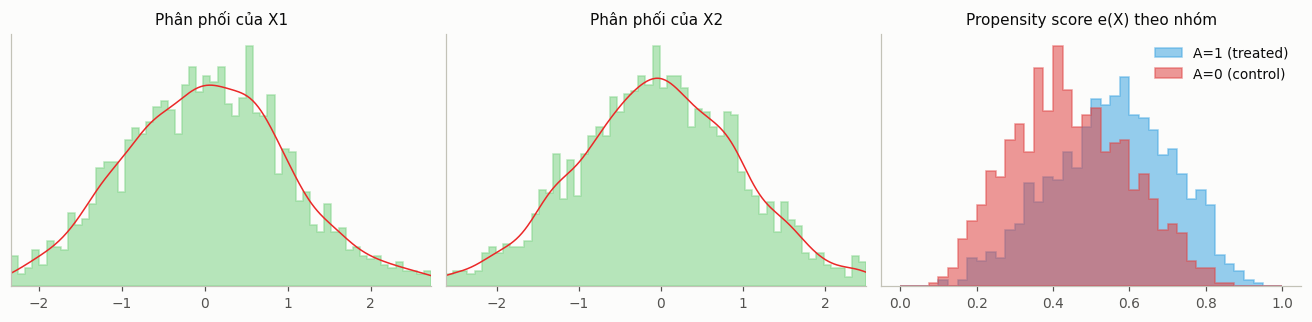

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.534,1.155,False,0.051,1.149,True
X2,0.452,1.084,False,-0.037,1.129,True


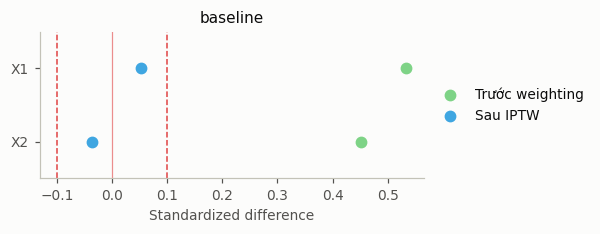

,n,ess,ess_ratio
toàn mẫu,2000,1734.264,0.867
treated (A=1),977,834.721,0.854
control (A=0),1023,900.303,0.880


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,2.522,2.027,2.027,2.034
bias,0.522,0.027,0.027,0.034


In [33]:
df = inspect_case("baseline", n=N, seed=SEED)

### 2. weak_overlap

$X_1 \sim N(0;1),\ X_2 \sim N(0;9)$. Phương sai lớn làm $e(X)$ dồn về 0/1, IPTW có trọng số cực đoan.

Kịch bản: weak_overlap  |  X1~N(0;1), X2~N(0;9)  |  n=2000, gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.484,0.008,0.993,0.003,35.791,0.459


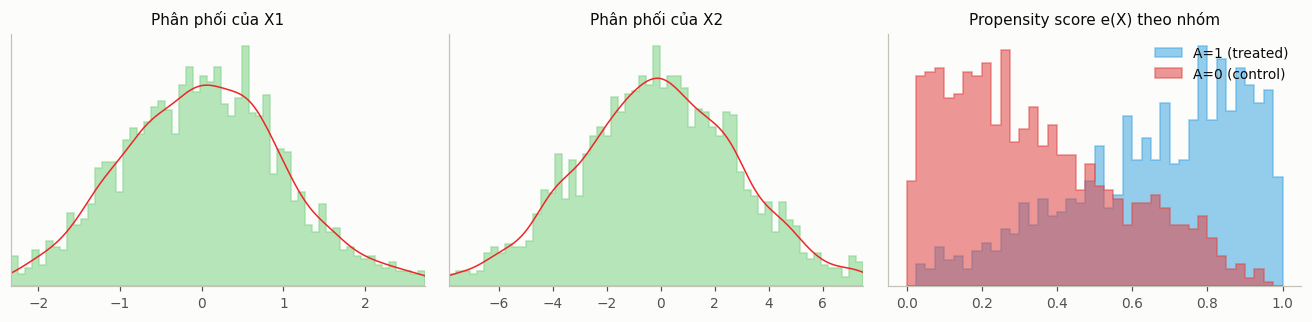

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.376,1.017,False,-0.045,0.992,True
X2,1.269,1.057,False,0.028,1.311,True


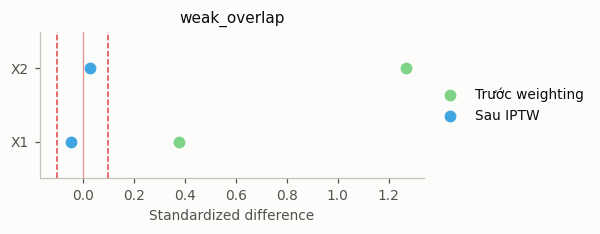

,n,ess,ess_ratio
toàn mẫu,2000,917.273,0.459
treated (A=1),967,373.854,0.387
control (A=0),1033,603.564,0.584


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,3.835,2.005,1.921,2.001
bias,1.835,0.005,-0.079,0.001


In [34]:
df = inspect_case("weak_overlap", n=N, seed=SEED)

### 3. outlier

$X_2 \sim t(df=2)$. Đuôi dày, phương sai vô hạn: vài điểm cực đoan chi phối IPTW và có leverage lớn trong OLS.

Kịch bản: outlier  |  X1~N(0;1), X2~t(df=2)  |  n=2000, gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.507,0.0,1.0,0.014,18.4,0.751


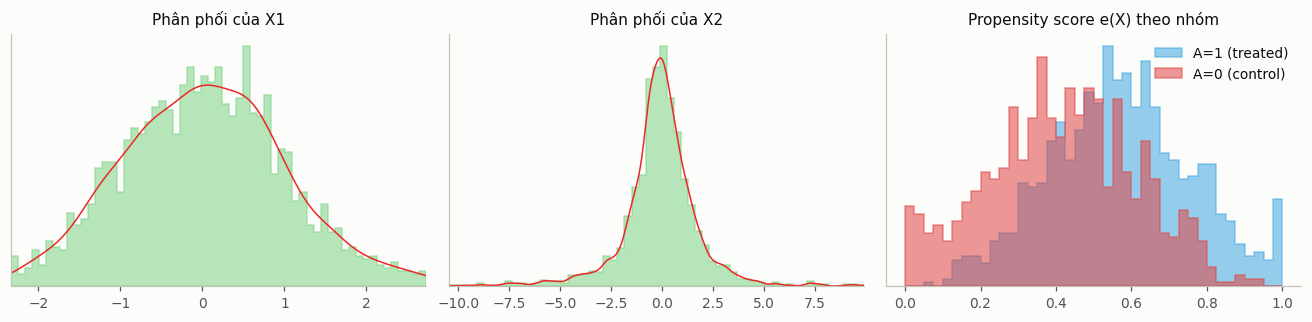

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.385,1.025,False,-0.060,0.958,True
X2,0.569,1.026,False,0.056,0.971,True


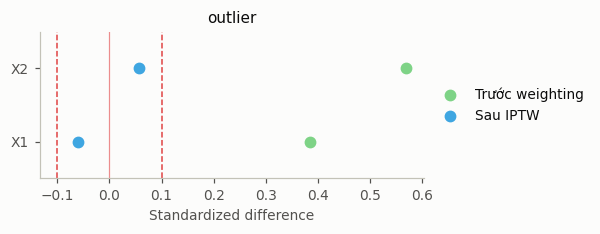

,n,ess,ess_ratio
toàn mẫu,2000,1502.579,0.751
treated (A=1),1015,781.286,0.770
control (A=0),985,721.784,0.733


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,2.982,1.988,2.169,1.999
bias,0.982,-0.012,0.169,-0.001


In [35]:
df = inspect_case("outlier", n=N, seed=SEED)

### 4. skewed

$X_2 \sim Exp(1)-1$. Lệch phải, đuôi nhẹ hơn $t$; thiếu overlap cục bộ ở đuôi phải.

Kịch bản: skewed  |  X1~N(0;1), X2~Exp(1)-1  |  n=2000, gamma0=0.01, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.505,0.102,0.974,0.0,10.953,0.883


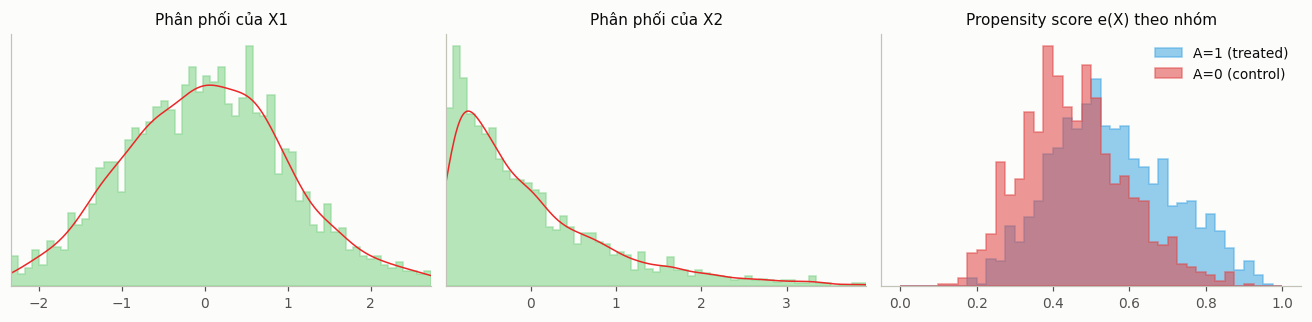

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.489,1.031,False,0.034,0.966,True
X2,0.437,2.234,False,0.038,1.157,True


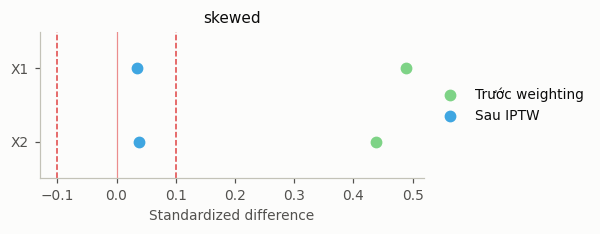

,n,ess,ess_ratio
toàn mẫu,2000,1766.369,0.883
treated (A=1),1010,914.019,0.905
control (A=0),990,854.097,0.863


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,2.429,1.953,1.948,1.942
bias,0.429,-0.047,-0.052,-0.058


In [36]:
df = inspect_case("skewed", n=N, seed=SEED)

### 5. bimodal

$X_2$ hai đỉnh tại $\pm 0.8$ (phương sai 1). Kỳ vọng ít khác baseline vì mô hình tham số vẫn đúng.

Kịch bản: bimodal  |  X1~N(0;1), X2~Bimodal  |  n=2000, gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.496,0.113,0.901,0.0,7.969,0.875


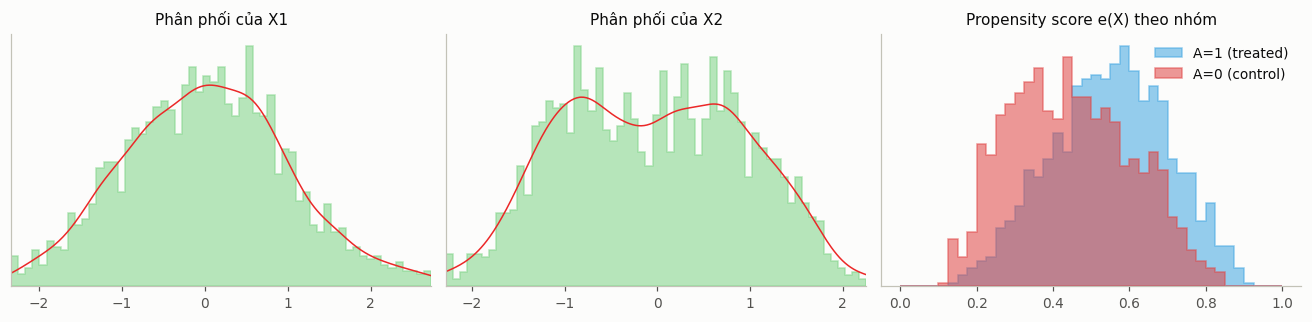

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.435,1.054,False,-0.035,1.025,True
X2,0.500,0.937,False,0.014,0.923,True


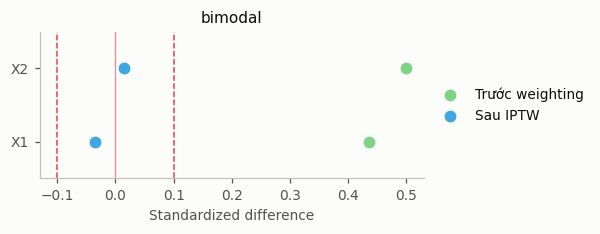

,n,ess,ess_ratio
toàn mẫu,2000,1750.145,0.875
treated (A=1),992,870.107,0.877
control (A=0),1008,880.043,0.873


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,2.486,2.015,2.022,2.014
bias,0.486,0.015,0.022,0.014


In [37]:
df = inspect_case("bimodal", n=N, seed=SEED)

### 6. skewed + outlier

$X_1 \sim Exp(1)-1,\ X_2 \sim t(df=2)$. Độ lệch kết hợp đuôi dày.

Kịch bản: skewed_outlier  |  X1~Exp(1)-1, X2~t(df=2)  |  n=2000, gamma0=0.01, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.486,0.0,1.0,0.012,58.305,0.548


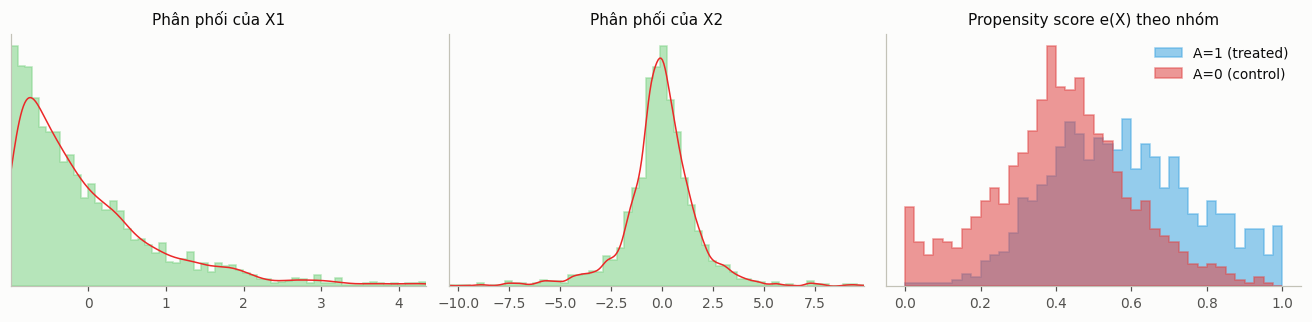

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.430,2.424,False,0.021,1.010,True
X2,0.575,1.131,False,-0.046,1.207,True


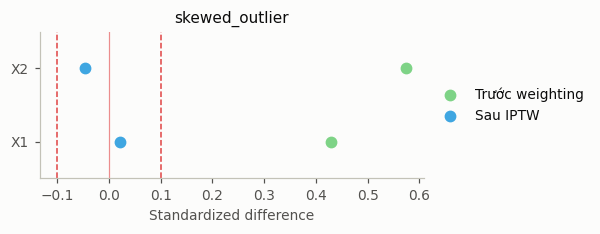

,n,ess,ess_ratio
toàn mẫu,2000,1095.572,0.548
treated (A=1),972,468.707,0.482
control (A=0),1028,653.933,0.636


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,3.038,2.048,2.108,2.07
bias,1.038,0.048,0.108,0.07


In [38]:
df = inspect_case("skewed_outlier", n=N, seed=SEED)

### 7. skewed + bimodal

$X_1 \sim Exp(1)-1,\ X_2$ bimodal.

Kịch bản: skewed_bimodal  |  X1~Exp(1)-1, X2~Bimodal  |  n=2000, gamma0=0.01, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.498,0.14,0.989,0.0,13.114,0.884


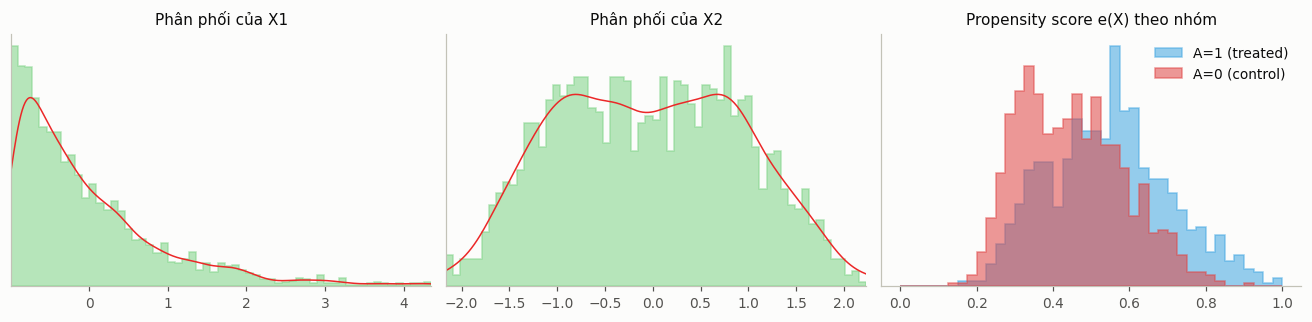

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.482,2.450,False,0.079,1.163,True
X2,0.399,1.017,False,-0.059,1.021,True


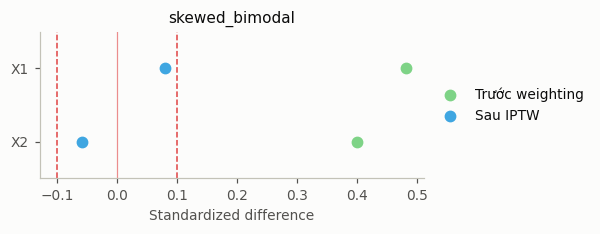

,n,ess,ess_ratio
toàn mẫu,2000,1768.464,0.884
treated (A=1),997,891.857,0.895
control (A=0),1003,876.607,0.874


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,2.441,2.003,2.008,1.999
bias,0.441,0.003,0.008,-0.001


In [39]:
df = inspect_case("skewed_bimodal", n=N, seed=SEED)

### 8. outlier + bimodal

$X_1 \sim t(df=2),\ X_2$ bimodal.

Kịch bản: outlier_bimodal  |  X1~t(df=2), X2~Bimodal  |  n=2000, gamma0=-0.00, ATE thật=2.0


,n,treated_rate,e_min,e_max,e_outside,max_weight,ess_ratio
giá trị,2000.0,0.486,0.0,1.0,0.011,41.383,0.669


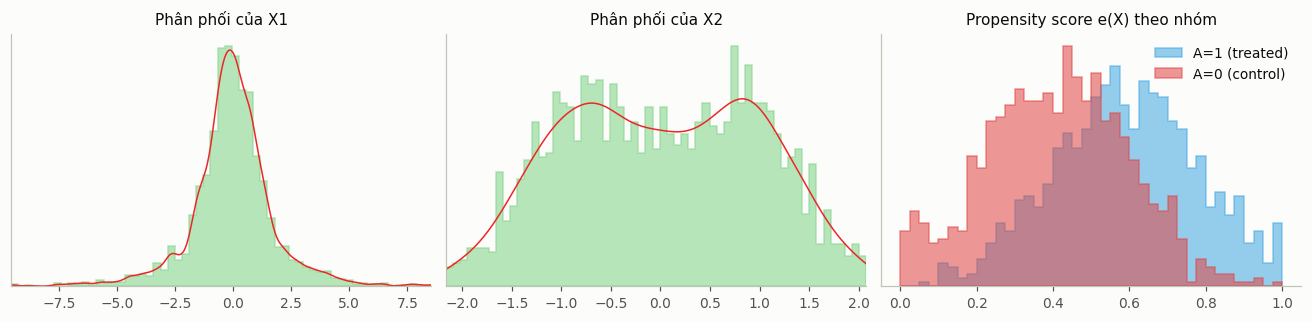

Balance trước / sau gán trọng số IPTW


,smd_before,vr_before,balanced_before,smd_after,vr_after,balanced_after
X1,0.668,1.039,False,0.095,0.906,True
X2,0.451,0.975,False,-0.014,0.962,True


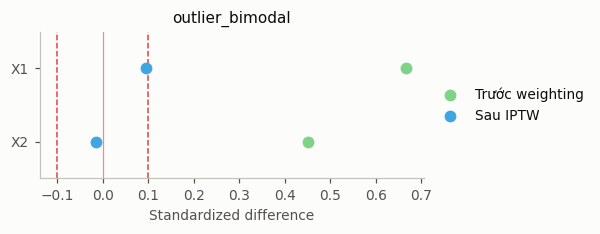

,n,ess,ess_ratio
toàn mẫu,2000,1338.149,0.669
treated (A=1),972,749.856,0.771
control (A=0),1028,611.825,0.595


ATE ước lượng (thật = 2.0)


,naive,ols,iptw,aipw
ATE_hat,3.072,2.062,2.132,2.127
bias,1.072,0.062,0.132,0.127


In [40]:
df = inspect_case("outlier_bimodal", n=N, seed=SEED)

## Trimming: có cứu được IPTW không?

`compare_trim` chạy một kịch bản với nhiều ngưỡng trim. Cột `clipped` là tỉ lệ quan sát bị clip, `ess_ratio` là ESS/n của trọng số sau clip.

In [41]:
def compare_trim(name, trims=(None, 0.01, 0.05, 0.1), n=2000, seed=251, use_estimated_ps=False):
    sim = Simulation(name, n=n, seed=seed)
    df = sim.generate()
    rows = {}
    for t in trims:
        est = estimate_all(df, use_estimated_ps=use_estimated_ps, trim=t)
        w = iptw_weights(df, trim=t)
        s = summarize(check_balance(df, trim=t))
        clipped = 0.0 if t is None else float(((df.e < t) | (df.e > 1 - t)).mean())
        rows["không trim" if t is None else f"trim={t}"] = {
            "iptw": est["iptw"], "aipw": est["aipw"], "ols": est["ols"],
            "clipped": clipped, "ess_ratio": w.sum() ** 2 / (w ** 2).sum() / len(df),
            "max_|SMD|_sau": s["max_abs_smd_after"], "can_bang_sau": s["all_balanced_after"],
        }
    print(f"{name}: ATE thật = {sim.ate}")
    return pd.DataFrame(rows).T

In [43]:
compare_trim("outlier").round(3)

outlier: ATE thật = 2.0


,iptw,aipw,ols,clipped,ess_ratio,max_|SMD|_sau,can_bang_sau
không trim,2.052883,2.00467,1.987596,0.0,0.75129,0.060485,True
trim=0.01,2.053858,2.004678,1.987596,0.0135,0.751336,0.060476,True
trim=0.05,2.060778,2.004772,1.987596,0.035,0.751822,0.061896,True
trim=0.1,2.105353,1.997894,1.987596,0.061,0.794421,0.094979,True


In [44]:
compare_trim("outlier_bimodal").round(3)

outlier_bimodal: ATE thật = 2.0


,iptw,aipw,ols,clipped,ess_ratio,max_|SMD|_sau,can_bang_sau
không trim,2.219713,2.112297,2.062338,0.0,0.669075,0.094531,True
trim=0.01,2.220439,2.112315,2.062338,0.011,0.66911,0.095125,True
trim=0.05,2.250014,2.097542,2.062338,0.028,0.746237,0.128511,False
trim=0.1,2.310508,2.103837,2.062338,0.056,0.795148,0.166736,False


## So sánh cả 8 kịch bản bằng mô phỏng lặp

Một lần chạy dễ gây nhiễu, nên `monte_carlo` lặp `reps` lần rồi trả về **bias** và **RMSE** của từng phương pháp.

In [49]:
METHODS = ["naive", "ols", "iptw", "aipw"]

def monte_carlo(name, n=N, reps=200, trim=None, use_estimated_ps=True, seed=SEED):
    sim = Simulation(name, n=n, seed=seed)
    est = pd.DataFrame([estimate_all(sim.generate(), use_estimated_ps=use_estimated_ps, trim=trim)
                        for _ in range(reps)])
    return pd.DataFrame({
        "bias": est.mean() - sim.ate,
        "rmse": np.sqrt(((est - sim.ate) ** 2).mean()),
    })

def mc_all(**kw):
    res = {k: monte_carlo(k, **kw) for k in SCENARIOS}
    bias = pd.DataFrame({k: v["bias"] for k, v in res.items()}).T[METHODS]
    rmse = pd.DataFrame({k: v["rmse"] for k, v in res.items()}).T[METHODS]
    return bias, rmse

bias, rmse = mc_all(n=N, reps=200)
print("Bias"); display(bias.round(3))
print("RMSE"); display(rmse.round(3))

Bias


,naive,ols,iptw,aipw
baseline,0.449,-0.003,-0.002,-0.002
weak_overlap,1.725,-0.003,-0.002,-0.003
outlier,0.993,-0.003,0.065,-0.002
skewed,0.432,-0.007,-0.007,-0.007
bimodal,0.454,-0.002,-0.001,-0.002
skewed_outlier,0.985,0.005,0.060,0.008
skewed_bimodal,0.437,0.001,0.002,0.000
outlier_bimodal,0.999,-0.002,0.093,-0.001


RMSE


,naive,ols,iptw,aipw
baseline,0.452,0.045,0.048,0.047
weak_overlap,1.726,0.052,0.163,0.068
outlier,1.002,0.044,0.320,0.057
skewed,0.436,0.049,0.054,0.049
bimodal,0.457,0.044,0.045,0.045
skewed_outlier,0.988,0.049,0.252,0.084
skewed_bimodal,0.440,0.043,0.053,0.044
outlier_bimodal,1.005,0.046,0.157,0.059


In [57]:
from matplotlib.colors import LinearSegmentedColormap, LogNorm

METHOD_COLORS = {"ols": BLUE, "iptw": ORANGE, "aipw": MUTED}


def plot_mc(bias, rmse, methods=("ols", "iptw", "aipw"), title=None):
    """
    Ba ô cùng hàng kịch bản: Bias | Độ lệch chuẩn | RMSE  (RMSE^2 = Bias^2 + SD^2).
    bias, rmse: DataFrame (index = kịch bản, cột = phương pháp), như kết quả của mc_all().
    naive mặc định bị bỏ vì quá lớn làm các phương pháp còn lại dính sát nhau.
    """
    sd = np.sqrt(np.clip(rmse ** 2 - bias ** 2, 0, None))
    panels = [("Bias (độ chệch)", bias), ("SD (độ biến động)", sd), ("RMSE (sai số tổng)", rmse)]
    names = list(bias.index)
    y = np.arange(len(names))

    fig, axes = plt.subplots(1, 3, figsize=(12, 0.42 * len(names) + 1.6), sharey=True)
    for ax, (ttl, tab) in zip(axes, panels):
        for yi in y:                                              # đường dẫn mắt theo hàng
            ax.axhline(yi, color="#e1e0d9", lw=0.6, zorder=1)
        for m in methods:
            ax.scatter(tab[m], y, s=48, color=METHOD_COLORS[m], label=m, zorder=3,
                       edgecolor="#fcfcfb", linewidth=1.2)        # viền nền tách các điểm chồng nhau
        if ttl.startswith("Bias"):
            ax.axvline(0, color=INK, lw=1, zorder=2)
        ax.set_title(ttl)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y); axes[0].set_yticklabels(names); axes[0].set_ylim(len(names) - 0.5, -0.5)
    axes[2].legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=11)
    fig.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()


def heatmap_mc(tab, title="RMSE theo kịch bản và phương pháp", fmt="{:.3f}"):
    """Bản đồ nhiệt có ghi số cho toàn bộ bảng (gồm cả naive). Thang màu log để thấy cả 0.04 lẫn 1.7."""
    cmap = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
    vals = tab.to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(0.95 * tab.shape[1] + 2.2, 0.42 * tab.shape[0] + 1.2))
    norm = LogNorm(vmin=vals[vals > 0].min(), vmax=vals.max())
    ax.imshow(vals, cmap=cmap, norm=norm, aspect="auto")
    for i in range(vals.shape[0]):
        for j in range(vals.shape[1]):
            ax.text(j, i, fmt.format(vals[i, j]), ha="center", va="center", fontsize=9,
                    color="white" if norm(vals[i, j]) > 0.55 else INK)
    ax.set_xticks(range(tab.shape[1])); ax.set_xticklabels(tab.columns)
    ax.set_yticks(range(tab.shape[0])); ax.set_yticklabels(tab.index)
    ax.xaxis.tick_top(); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.grid(False)
    ax.set_title(title, loc="center", pad=28)
    fig.tight_layout(); plt.show()

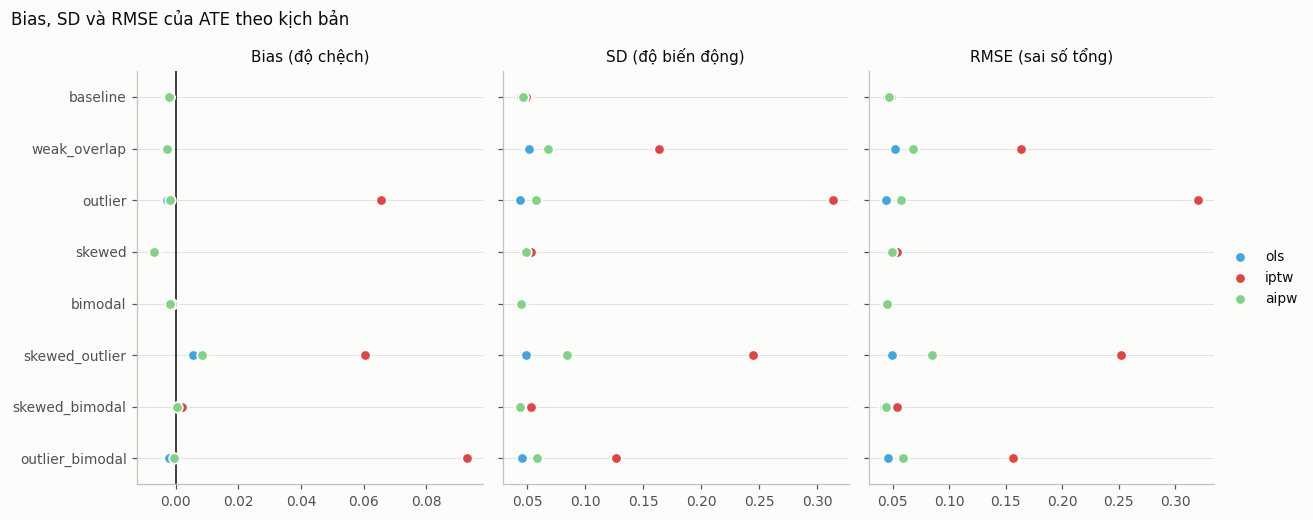

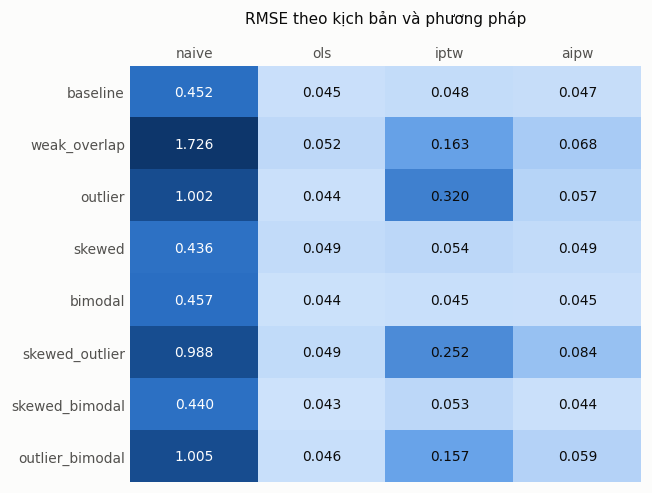

In [58]:
plot_mc(bias, rmse, title="Bias, SD và RMSE của ATE theo kịch bản")
heatmap_mc(rmse)